In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.metrics import accuracy_score, roc_curve, auc
from sklearn.model_selection import KFold
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from google.colab import drive

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from keras.layers import Dense, Input, Dropout
from tensorflow.keras import initializers
from keras.utils import to_categorical
from keras.utils import plot_model

import gspread
import pandas as pd
from google.colab import auth
import google.auth

# Higgs

In [ ]:
# Load the Higgs dataset
higgs_data = fetch_openml(name='higgs', version=1, as_frame =True)
higgs_data_df = higgs_data.frame

# --- 1. DATA PREP & SCALING ---
# We fill NaNs with the mean to preserve as many collision events as possible
X = higgs_data_df.drop(columns=['class']).fillna(higgs_data_df.mean())
Y = higgs_data_df ['class'].astype(int)

feature_names = X.columns

# Dividing in 80% training and 20% test
#The training is used for the extimation
#The test is used for the accuracy and ROC
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

KeyboardInterrupt: 

##Build the model

In [ ]:
print(X_test.shape)

pca_full = PCA().fit(X_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
# Select N to capture 90% of the statistical information
N_COMPONENTS = np.where(cumulative_variance >= 0.90)[0][0] + 1

pca = PCA(n_components=N_COMPONENTS)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print(X_test.shape)

pca_full = PCA().fit(X_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
# Select N to capture 90% of the statistical information
N_COMPONENTS = np.where(cumulative_variance >= 0.90)[0][0] + 1

pca = PCA(n_components=N_COMPONENTS)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)



print(X_test.shape)

(19610, 28)
(19610, 16)
(19610, 13)


In [ ]:
model = Sequential()
model.add(Input((X_test.shape[1],)))
model.add(Dense(64, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(32, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(16, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(8, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(1, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))

# Compile the model
#lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
#    initial_learning_rate=1e-2,
#    decay_steps=10000,
#    decay_rate=0.9)

#opt = keras.optimizers.Adam(learning_rate=0.001)  #Adam optimizer
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_57 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
history = model.fit(X_train, Y_train, epochs=100, batch_size=64, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5200 - loss: 0.8245 - val_accuracy: 0.5435 - val_loss: 0.6900
Epoch 2/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5419 - loss: 0.6891 - val_accuracy: 0.5356 - val_loss: 0.6886
Epoch 3/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5517 - loss: 0.6858 - val_accuracy: 0.5545 - val_loss: 0.6834
Epoch 4/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5633 - loss: 0.6814 - val_accuracy: 0.5509 - val_loss: 0.6831
Epoch 5/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5677 - loss: 0.6798 - val_accuracy: 0.5486 - val_loss: 0.6846
Epoch 6/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5745 - loss: 0.6770 - val_accuracy: 0.5713 - val_loss: 0.6785
Epoch 7/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5798 - loss: 0.6748 - val_accuracy: 0.5734 - val_loss: 0.6812
Epoch 8/100
981/981 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5866 - loss: 0.6720 - val_accu

##Evaluate the model

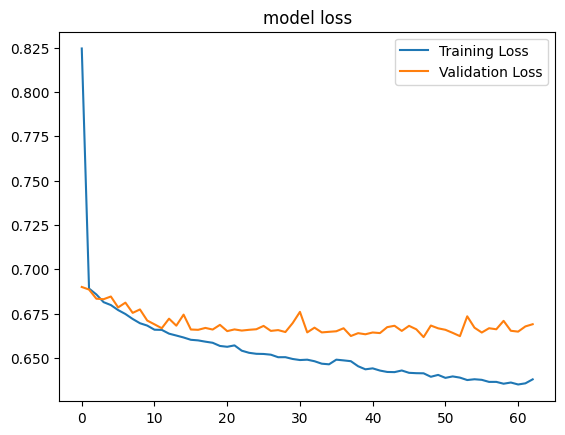

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title('model loss')
plt.legend()
plt.show()

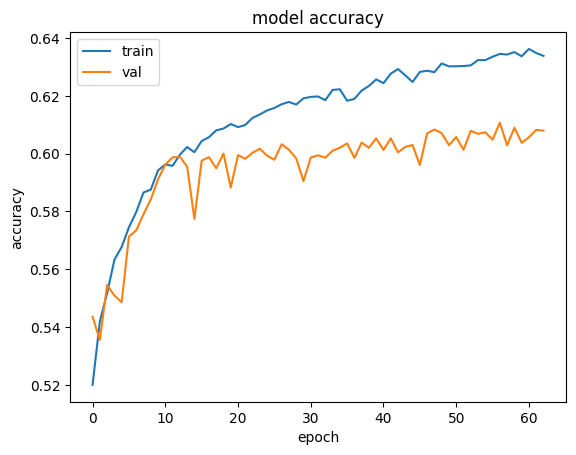

In [ ]:
plt.plot(history.history['accuracy'], label="Training accuracy")
plt.plot(history.history['val_accuracy'], label="Validation accuracy")
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

613/613 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
2452/2452 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


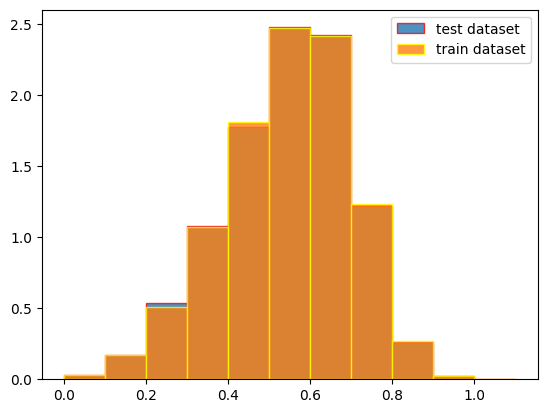

In [ ]:
#predict the outcome on the test sample and plot the score
prediction_test = model.predict(X_test)
plt.hist(prediction_test, label='test dataset', alpha=.8, edgecolor='red', bins=np.arange(prediction_test.min(), prediction_test.max() + 0.1, 0.1), density=True)

#predict the outcome on the test sample and plot the score
prediction_train = model.predict(X_train)
plt.hist(prediction_train, label='train dataset', alpha=.8, edgecolor='yellow', bins=np.arange(prediction_test.min(), prediction_test.max() + 0.1, 0.1), density=True)

plt.legend()
plt.show()

In [ ]:
print(prediction_test.max())

1.037102


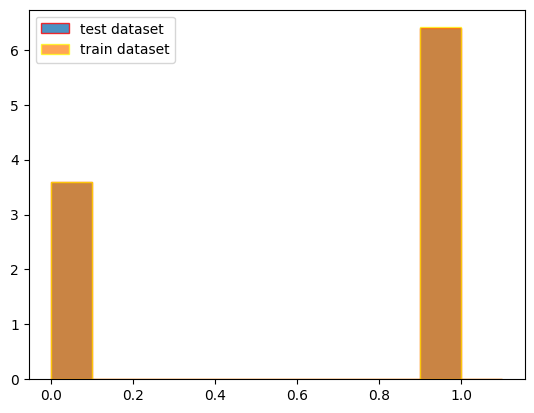

In [ ]:
#cast the score to a bool value
prediction_test_rounded = np.round(prediction_test) #cut the score in half
plt.hist(prediction_test_rounded, label='test dataset', alpha=.8, edgecolor='red', bins=np.arange(prediction_test_rounded.min(), prediction_test_rounded.max() + 0.2, 0.1), density=True)

prediction_train_rounded = np.round(prediction_train) #cut the score in half
plt.hist(prediction_train_rounded, label='train dataset', alpha=.7, edgecolor='yellow', bins=np.arange(prediction_test_rounded.min(), prediction_test_rounded.max() + 0.2, 0.1), density=True)

plt.legend()
plt.show()

In [ ]:
diff_test = abs(prediction_test_rounded.flatten() - Y_test)
print('Accuracy on test data: {}'.format(1 - np.sum(diff_test)/diff_test.size))

diff_train = abs(prediction_train_rounded.flatten() - Y_train)
print('Accuracy on train data: {}'.format(1 - np.sum(diff_train)/diff_train.size))

Accuracy on test data: 0.6060173380928098
Accuracy on train data: 0.6320499745028048


##ROC Curve



The Receiver Operating Characteristic (ROC) curve is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied. It plots the True Positive Rate (TPR) against the False Positive Rate (FPR) at various threshold settings. The Area Under the Curve (AUC) provides an aggregate measure of performance across all possible classification thresholds. A perfect classifier would have an AUC of 1, while a purely random classifier would have an AUC of 0.5.

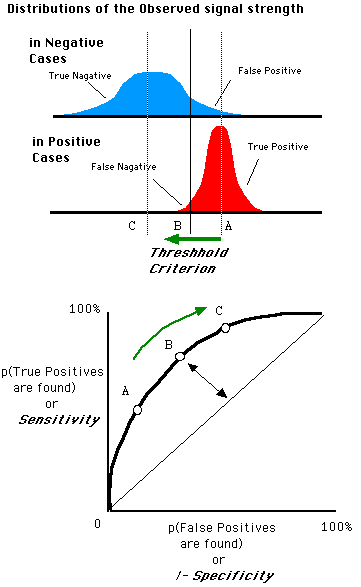

In [ ]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

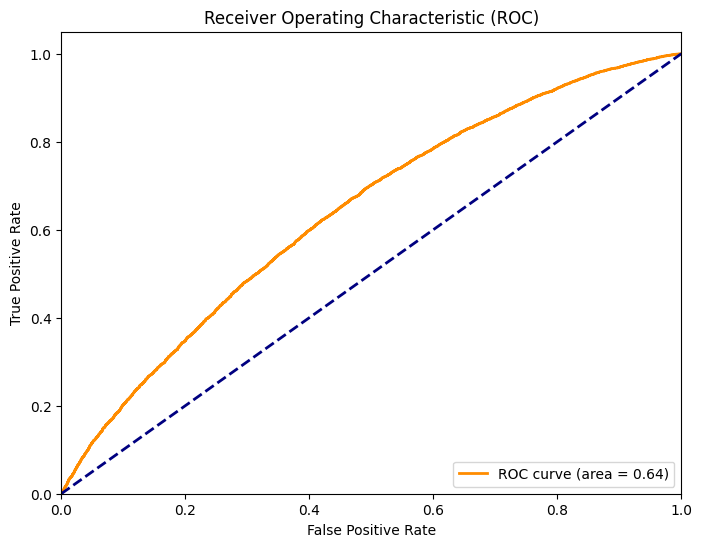

In [ ]:
fpr, tpr, thresholds = roc_curve(Y_test, prediction_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

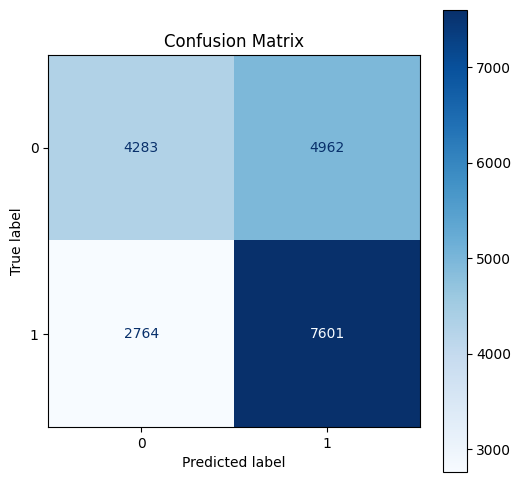

In [ ]:
cm = confusion_matrix(Y_test, prediction_test_rounded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix')
plt.show()

# Jets

In [23]:
data_jet = fetch_openml("hls4ml_lhc_jets_hlf", parser="auto")
X_jet, Y_jet = data_jet["data"], data_jet["target"]

Xj_train, Xj_test, Yj_train, Yj_test = train_test_split(X_jet, Y_jet, test_size=0.2, random_state=42, stratify=Y_jet)


In [24]:
print(Xj_test.shape)

pca_full = PCA().fit(Xj_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
# Select N to capture 90% of the statistical information
N_COMPONENTS = np.where(cumulative_variance >= 0.90)[0][0] + 1

pca = PCA(n_components=N_COMPONENTS)
Xj_train = pca.fit_transform(Xj_train)
Xj_test = pca.transform(Xj_test)

print(Xj_test.shape)

(166000, 16)
(166000, 1)


In [25]:
model = Sequential()
model.add(Input((Xj_test.shape[1],)))
model.add(Dense(16, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(8, activation='relu', kernel_initializer='random_normal', bias_initializer='zeros'))
model.add(Dense(5, activation='softmax', kernel_initializer='random_normal', bias_initializer='zeros'))

Yj_train = pd.get_dummies(Yj_train).astype('float32')
Yj_test = pd.get_dummies(Yj_test).astype('float32')

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
history = model.fit(Xj_train, Yj_train, epochs=25, batch_size=64, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 25s 3ms/step - accuracy: 0.6136 - loss: 1.0445 - val_accuracy: 0.6293 - val_loss: 0.9948
Epoch 2/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 25s 3ms/step - accuracy: 0.6312 - loss: 0.9912 - val_accuracy: 0.6383 - val_loss: 0.9895
Epoch 3/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.6347 - loss: 0.9811 - val_accuracy: 0.6417 - val_loss: 0.9790
Epoch 4/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 50s 4ms/step - accuracy: 0.6389 - loss: 0.9746 - val_accuracy: 0.6376 - val_loss: 0.9749
Epoch 5/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 61s 7ms/step - accuracy: 0.6440 - loss: 0.9680 - val_accuracy: 0.6490 - val_loss: 0.9669
Epoch 6/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 61s 5ms/step - accuracy: 0.6479 - loss: 0.9631 - val_accuracy: 0.6516 - val_loss: 0.9549
Epoch 7/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 25s 3ms/step - accuracy: 0.6475 - loss: 0.9609 - val_accuracy: 0.6457 - val_loss: 0.9568
Epoch 8/25
8300/8300 ━━━━━━━━━━━━━━━━━━━━ 23s 3ms/step - accuracy: 0.6452 - loss: 0

KeyboardInterrupt: 

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title('model loss')
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history['accuracy'], label="Training accuracy")
plt.plot(history.history['val_accuracy'], label="Validation accuracy")
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [ ]:
#predict the outcome on the test sample and plot the score
prediction_test = model.predict(Xj_test)
plt.hist(prediction_test, label='test dataset', alpha=.8, edgecolor='red', bins=np.arange(prediction_test.min(), prediction_test.max() + 0.1, 0.1), density=True)

#predict the outcome on the test sample and plot the score
prediction_train = model.predict(Xj_train)
plt.hist(prediction_train, label='train dataset', alpha=.8, edgecolor='yellow', bins=np.arange(prediction_test.min(), prediction_test.max() + 0.1, 0.1), density=True)

plt.legend()
plt.show()


In [ ]:
print(prediction_test.max())

In [ ]:
#cast the score to a bool value
prediction_test_rounded = np.round(prediction_test) #cut the score in half
plt.hist(prediction_test_rounded, label='test dataset', alpha=.8, edgecolor='red', bins=np.arange(prediction_test_rounded.min(), prediction_test_rounded.max() + 0.2, 0.1), density=True)

prediction_train_rounded = np.round(prediction_train) #cut the score in half
plt.hist(prediction_train_rounded, label='train dataset', alpha=.7, edgecolor='yellow', bins=np.arange(prediction_test_rounded.min(), prediction_test_rounded.max() + 0.2, 0.1), density=True)

plt.legend()
plt.show()

In [ ]:
diff_test = abs(prediction_test_rounded.flatten() - Y_test)
print('Accuracy on test data: {}'.format(1 - np.sum(diff_test)/diff_test.size))

diff_train = abs(prediction_train_rounded.flatten() - Y_train)
print('Accuracy on train data: {}'.format(1 - np.sum(diff_train)/diff_train.size))

In [ ]:
fpr, tpr, thresholds = roc_curve(Y_test, prediction_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

In [ ]:
cm = confusion_matrix(Y_test, prediction_test_rounded)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix')
plt.show()

# Solar Panels

In [ ]:

drive.mount('/content/drive')

auth.authenticate_user()
creds, _ = google.auth.default()
gc = gspread.authorize(creds)

sheet_url_gen = 'https://docs.google.com/spreadsheets/d/1RKSQlNbXGOV17Y6SQA2KJAYKz-22dKPftEtG4BVI75E/edit?usp=sharing'
sheet_url_weather = 'https://docs.google.com/spreadsheets/d/1ED_DOJcOMZKGc5rDm9Ch1PBCRQ7KKpl3qgJOLXygAb0/edit?usp=sharing'

worksheet_gen = gc.open_by_url(sheet_url_gen).sheet1
worksheet_weather = gc.open_by_url(sheet_url_weather).sheet1

data_gen = worksheet_gen.get_all_values()
data_weather = worksheet_weather.get_all_values()

df_gen = pd.DataFrame(data_gen[1:], columns=data_gen[0])
df_weather = pd.DataFrame(data_weather[1:], columns=data_weather[0])

display(df_gen.head())
display(df_weather.head())

Mounted at /content/drive


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0,0,0,6259559
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0,0,0,6183645
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0,0,0,6987759
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0,0,0,7602960
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0,0,0,7158964


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184.316.133.333.300,142939.54.00,0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084.588.666.666.600,22.761.667.866.666.600,0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935.752.600.000.000,22.592.305.533.333.300,0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,141045.44.00,22.360.852.133.333.300,0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621.525.357.142.800,22.165.422.642.857.100,0
